In [1]:
%run 00_utils.ipynb

%load_ext autoreload
%autoreload 2

Root-Verzeichnis: /home/jessh/Study/Bachelor-Thesis


In [2]:
from pathlib import Path
import cv2, os
import numpy as np
from data_handler.dataset import AntiUAVDataset
import albumentations as A

from augmentations.ir_camara_effects import thermal_histogram_compression, thermal_histogram_shift, simulate_fpn_corruption, add_common_mode_noise

/home/jessh/Study/Bachelor-Thesis/.venv/lib/python3.10/site-packages/albumentations/core/composition.py:331: UserWarning: Got processor for bboxes, but no transform to process it.
  self._set_keys()
/home/jessh/Study/Bachelor-Thesis/src/data_handler/dataset.py:62: UserWarning: Argument(s) 'var_limit' are not valid for transform GaussNoise
  A.GaussNoise(var_limit=(10.0, 50.0), p=0.3),
/home/jessh/Study/Bachelor-Thesis/src/data_handler/dataset.py:77: UserWarning: Argument(s) 'shift_limit' are not valid for transform OpticalDistortion
  A.OpticalDistortion(distort_limit=0.05, shift_limit=0.05, p=0.2),
/home/jessh/Study/Bachelor-Thesis/src/data_handler/dataset.py:78: UserWarning: Argument(s) 'distort_range' are not valid for transform GridDistortion
  A.GridDistortion(num_steps=5, distort_range=(-0.1, 0.1), p=0.2),


In [3]:
train_data = AntiUAVDataset(TRAINING_DIR, debug=True)

In [4]:
IMAGE_ID = 100000

In [5]:
def wrap(transform):
    # Falls nur ein einzelner Transform übergeben wurde, in eine Liste packen
    if not isinstance(transform, (list, tuple)):
        transform = [transform]
        
    return A.Compose(
        transform, 
        bbox_params=A.BboxParams(format='coco', label_fields=['class_labels']),
        save_applied_params=True
    )

PROB = 1.0

In [6]:

transforms = [
    # 1. Simuliert thermisches Rauschen des Sensors
    A.GaussNoise(var_limit=(1.0, 5.0), p=PROB),
    
    # 2. Simuliert Thermal Blooming (leichtes Verschwimmen der Hitze)
    A.GaussianBlur(blur_limit=(3, 5), p=PROB),
    
    # 3. Simuliert Thermal Crossover / wechselnde Temperaturkontraste
    A.RandomBrightnessContrast(brightness_limit=0.15, contrast_limit=0.2, p=PROB),
    
    # 4. Verbessert/verschlechtert lokale Kontraste (wie echte Wärmebilder)
    A.CLAHE(clip_limit=2.0, tile_grid_size=(8, 8), p=PROB),
    
    # 5. Simuliert Hitzeflimmern in Bodennähe
    [A.OpticalDistortion(distort_limit=0.05, shift_limit=0.05, p=PROB),
     A.GridDistortion(num_steps=5, distort_range=(-0.1, 0.1), p=PROB)],

    A.Downscale(
        scale_range=(0.05, 0.25),
        interpolation_pair={'downscale': cv2.INTER_NEAREST, 'upscale': cv2.INTER_LINEAR},
        p=PROB
    ),
]


transforms =[
    A.CLAHE(clip_limit=4.0, tile_grid_size=(8, 8), p=PROB),

# 1. Globales Histogramm-Shifting (Simuliert globale Temperatur-Drifts)
    A.Lambda(
        image=lambda img, **kw: thermal_histogram_shift(img, delta_limit=35), 
        p=PROB
    ),
    
    # 2. Histogramm-Kompression (Simuliert Thermal Crossover / niedrigen SCR)
    A.Lambda(
        image=lambda img, **kw: thermal_histogram_compression(img, gamma_min=0.4, gamma_max=0.85), 
        p=PROB
    ),
]

b_show_org = True
for transform in transforms:
    train_data.transform = wrap(transform)
    img, target, img_org = train_data[IMAGE_ID]
    continue

    if b_show_org:
        print(f"ORG:    {target['img_path']}")
        show_img(img_org)
        print("\n")
        b_show_org = not b_show_org
        
    
    print(" ".join([k[0] for k in target["applied_transforms"]]))
    show_img(img)

/tmp/ipykernel_164549/1075926446.py:3: UserWarning: Argument(s) 'var_limit' are not valid for transform GaussNoise
  A.GaussNoise(var_limit=(1.0, 5.0), p=PROB),
/tmp/ipykernel_164549/1075926446.py:15: UserWarning: Argument(s) 'shift_limit' are not valid for transform OpticalDistortion
  [A.OpticalDistortion(distort_limit=0.05, shift_limit=0.05, p=PROB),
/tmp/ipykernel_164549/1075926446.py:16: UserWarning: Argument(s) 'distort_range' are not valid for transform GridDistortion
  A.GridDistortion(num_steps=5, distort_range=(-0.1, 0.1), p=PROB)],
/tmp/ipykernel_164549/1075926446.py:30: UserWarning: Using lambda is incompatible with multiprocessing. Consider using regular functions or partial().
  A.Lambda(
/tmp/ipykernel_164549/1075926446.py:36: UserWarning: Using lambda is incompatible with multiprocessing. Consider using regular functions or partial().
  A.Lambda(


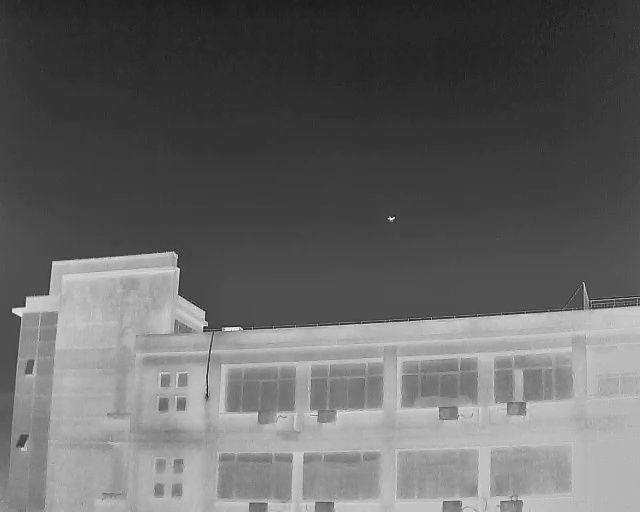

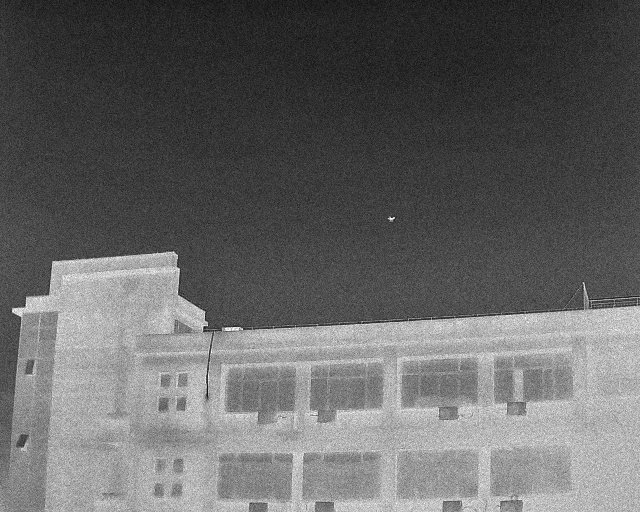

In [7]:
from augmentations.ir_camara_effects import fpn

img, target, img_org = train_data[IMAGE_ID]
noisy_img = fpn(img_org)

show_img(img_org)
show_img(noisy_img)

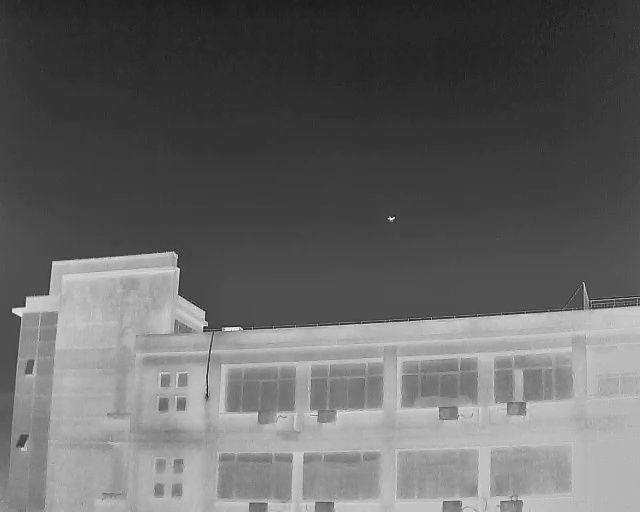

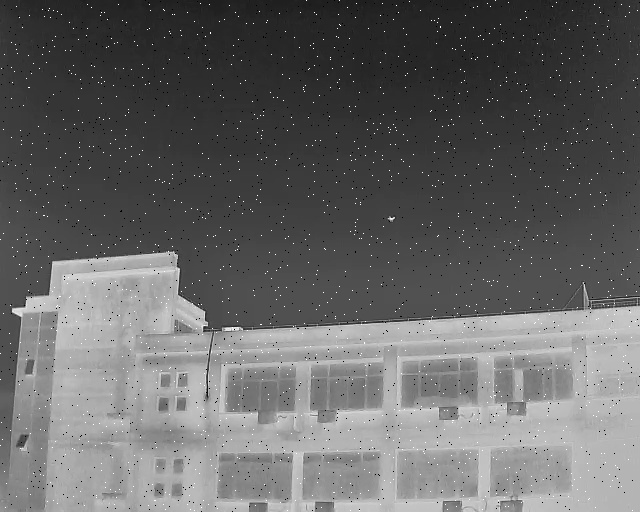

In [8]:
from augmentations.ir_camara_effects import salt_and_peper

img, target, img_org = train_data[IMAGE_ID]
noisy_img = salt_and_peper(img_org, s_max=255)

show_img(img_org)
show_img(noisy_img)

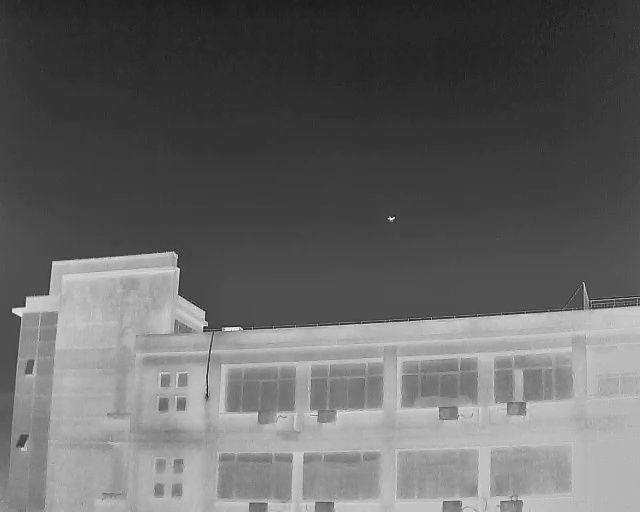

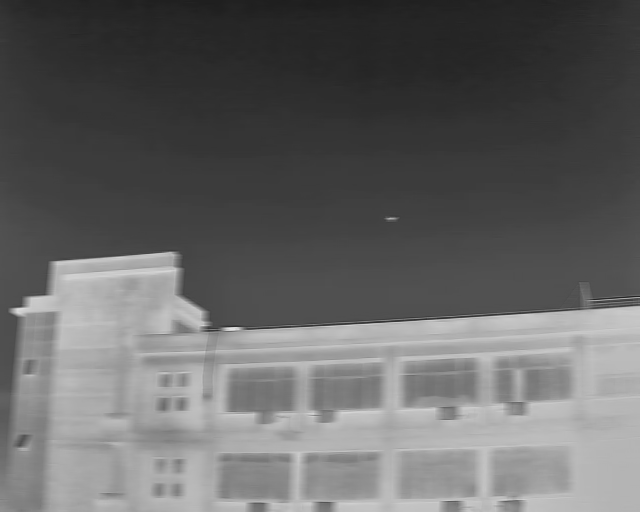

In [9]:
from augmentations.ir_camara_effects import motion_blur

img, target, img_org = train_data[IMAGE_ID]
noisy_img = motion_blur(img_org, tau_im=25.0, kernel_length=10, noise_std=0.0)

show_img(img_org)
show_img(noisy_img)

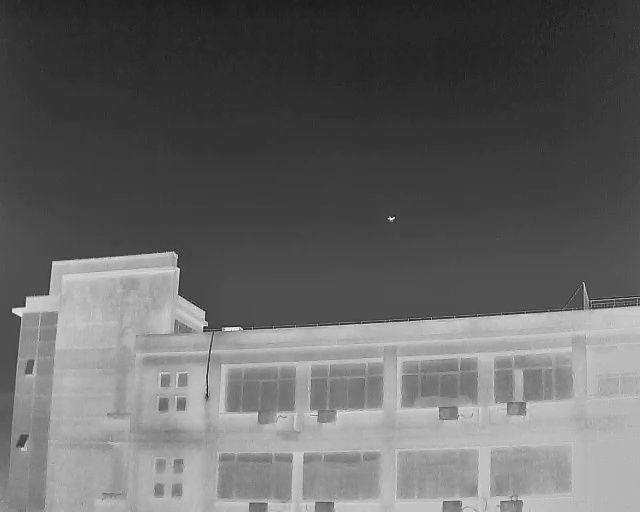

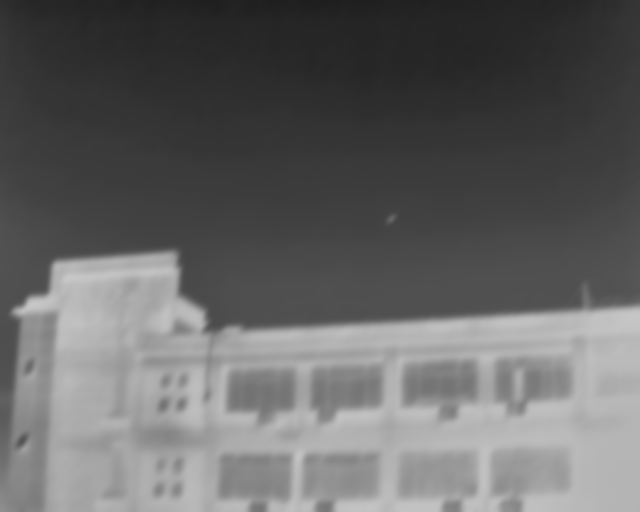

In [10]:
from augmentations.ir_camara_effects import blurring_with_psf

img, target, img_org = train_data[IMAGE_ID]
noisy_img = blurring_with_psf(
    img_org, 
    sigma_0=2.0, # stärke
    rho=2.0, 
    theta=np.radians(320), # richtung
    noise_std=0.00
)

show_img(img_org)
show_img(noisy_img)

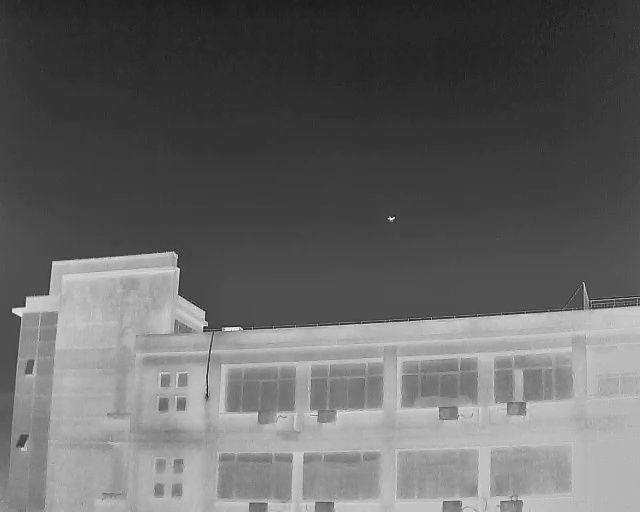

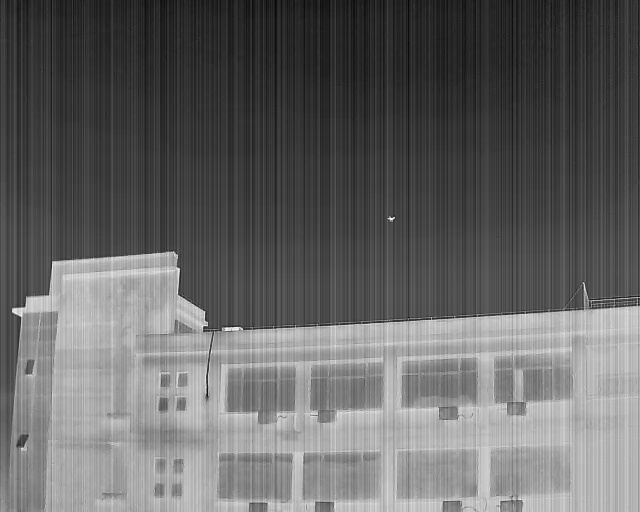

In [12]:
from augmentations.ir_camara_effects import stripe_noise

noisy_img = stripe_noise(
    img_org, 
    beta=15.1
)

show_img(img_org)
show_img(noisy_img)